**-Carga de librerias necesarias:**

In [1]:
import numpy as np

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

**-Definicion de las funciones de activacion de la capa de salida y oculta junto con sus derivadas:**

In [2]:
#definir funciones de activacion y derivada

def tanh(x):   #funcion activacion capa oculta
  return np.tanh(x)

def derivada_tanh(x):  #derivada para backpropagation y actualizacion de pesos con gradiente descendente
  return 1 - np.tanh(x)**2

def sigmoide(x):
    return 1 / (1 + np.exp(-x))


#**Creacion de la clase MLP:**

In [7]:
class autoEncoder:
  def __init__(self, input_size, hidden_layers, output_size):

    self.weights = []
    self.biases = []

    #inicializacion de pesos con xavier/glorot initialization
    layer_sizes = [input_size] + hidden_layers + [output_size]    #une en una lista

    for layer in range(len(layer_sizes)-1): #si hay n capas hay n-1 matrices de pesos
      input_dim = layer_sizes[layer]      #obtiene el la cantidad de neuronas de la capa de origen
      output_dim = layer_sizes[layer + 1]  #y de la capa de destino para la conexion actual

      limit = np.sqrt(6 / (input_dim + output_dim))

      W = np.random.uniform(-limit, limit, size=(input_dim, output_dim))  #la columna x contiene los pesos que le entran a la neurona x
      b = np.zeros(output_dim)

      self.weights.append(W)
      self.biases.append(b)


  def feed_forward(self, x):

    netas = []
    activaciones = [x]  #guarda las activaciones de la capa0 (la de entrada), que son los datos de entrada

    for i in range(len(self.weights)):
      neta = activaciones[i] @ self.weights[i] + self.biases[i]
      netas.append(neta)

      if i == len(self.weights)-1:
        activacion = sigmoide(neta)

      else:
        activacion = tanh(neta)

      activaciones.append(activacion)

    return activacion, netas, activaciones



  def back_propagation(self, y, y_pred, activations, netas):

    m = y.shape[0]  #numero de registros para obtener el gradiente promedio
    n_features = y.shape[1] #numero caracteristicas por muestra

    dW = [None] * len(self.weights)   #crea una lista llena de None para guardar el gradiente de los pesos
    db = [None] * len(self.biases)

    # Gradiente de la **capa de salida**
    delta = (2 / (m * n_features)) * (y_pred - y) * (y_pred * (1 - y_pred))   #error en la capa de salida

    dW[-1] = activations[-2].T @ delta  #multiplica la salida de la ultima capa oculta "[-2]" traspuesta por el error delta
    db[-1] = np.sum(delta, axis=0)     #el gradiente del bias es el delta (suma los delta de la fila)


    #retroceder por las capas ocultas
    for l in range(len(self.weights) - 2, -1, -1):  #recorre las capas desde la penultima hasta la primera disminuyendo de una en una

        delta = (delta @ self.weights[l + 1].T) * derivada_tanh(netas[l])  #multiplica los delta de la capa siguiente por los pesos de la capa siguiente que son las salidas de
                                                                        #esa capa y los multiplica por dy/dz

        dW[l] = activations[l].T @ delta   #calcula el gradiente de la capa l (dz/dw = x) -> por eso usa la activacion (ejemplo: en la acapa 0 la activacion seria
                                              # igual a x)
        db[l] = np.sum(delta, axis=0)    #el dz/db es igual a 1

    return dW, db



  def gradiente_descendente(self, dW, db, ln):

      for i in range(len(self.weights)):

        self.weights[i] -= ln * dW[i]
        self.biases[i] -= ln * db[i]



  def fit(self, x, epocas, ln, batch_size):
      #pasar y en one hot
      n = x.shape[0]
      loss_history = []
      for epoca in range(epocas):
        idx = np.random.permutation(n)

        for s in range(0, n, batch_size):
          xb = x[idx[s:s+batch_size]]
          x_reconstruida, netas, activations = self.feed_forward(xb)
          dW, db = self.back_propagation(xb, x_reconstruida, activations, netas)
          self.gradiente_descendente(dW, db, ln)

        loss = mse(x, self.predict(x))
        loss_history.append(loss)

          #mostrar progreso
        if epoca % 10 == 0:
            print(f"Epoch {epoca}: Loss = {loss:.6f}")

      return loss_history  #devuelve el historial de la perdida durante las epocas del entrenamiento


  def predict(self, x_train):

      x_reconstruida, _, _ = self.feed_forward(x_train)
      return x_reconstruida


  #def predict_proba(self, x_train):

   #   y_pred, _, _ = self.feed_forward(x_train)
    #  return y_pred



**-Definicion de la funcion de perdida (categorical cross entropy):**

In [4]:
def mse(x, x_reconstruida):

  mse = np.mean((x-x_reconstruida)**2)

  return mse


**-Preprocesamiento de los datos:**

In [6]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False) #importar el dataset

x = mnist.data / 255.0            # (70000, 784), **normalizado** a [0, 1]
y = mnist.target.astype(int)      # las etiquetas vienen como texto, hay que pasarlas a int

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=10000, random_state=42, stratify=y)  #partición datos para test y train

encoder = OneHotEncoder(sparse_output=False) #one hot encoding para las etiquetas
y_train_oh = encoder.fit_transform(y_train.reshape(-1, 1)) #etiquetas entrenamiento   #primero reshape y luego encoder

print(x_train.shape, y_train_oh.shape, x_test.shape, y_test.shape)

(60000, 784) (60000, 10) (10000, 784) (10000,)


In [8]:
x.shape

(70000, 784)

**-Instanciar el MLP:**

In [20]:
model = autoEncoder(
    input_size=784,
    hidden_layers=[128, 64, 128],
    output_size=784)

historial = model.fit(
    x_train,
    epocas=150,
    ln=1,  #0.7
    batch_size=128)

x_reconstruida = model.predict(x_test)
print("MSE test:", mse(x_test, x_reconstruida))

Epoch 0: Loss = 0.069871
Epoch 10: Loss = 0.062556
Epoch 20: Loss = 0.049698
Epoch 30: Loss = 0.040145
Epoch 40: Loss = 0.033462
Epoch 50: Loss = 0.029634
Epoch 60: Loss = 0.026671
Epoch 70: Loss = 0.024506
Epoch 80: Loss = 0.022785
Epoch 90: Loss = 0.021248
Epoch 100: Loss = 0.019904
Epoch 110: Loss = 0.018757
Epoch 120: Loss = 0.017758
Epoch 130: Loss = 0.016891
Epoch 140: Loss = 0.016131
MSE test: 0.015571673579827977


In [21]:
#baseline: MSE de predecir siempre la imagen promedio de train (cota que el autoencoder debe superar)
baseline = np.mean((x_test - x_train.mean(axis=0))**2)
print("MSE baseline (imagen promedio):", baseline)   # ≈ 0.0672
print("MSE autoencoder:", mse(x_test, x_reconstruida)) # ≈ 0.0238

MSE baseline (imagen promedio): 0.0672116005785411
MSE autoencoder: 0.015571673579827977


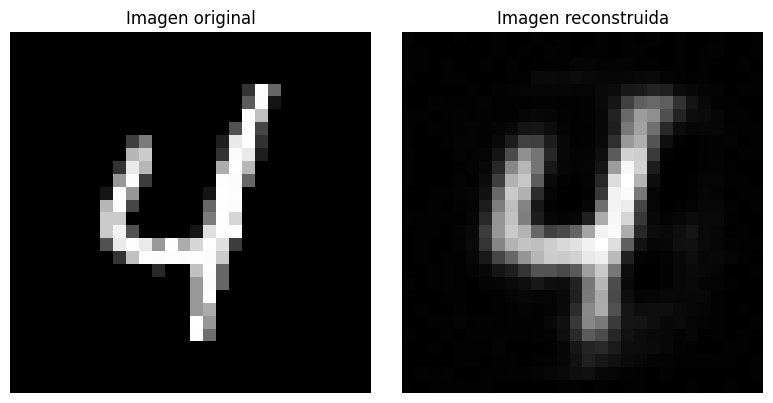

In [22]:
i = 1

imagen_original = x_test[i]

#reconstruirla con el autoencoder
imagen_reconstruida = model.predict(
    imagen_original.reshape(1, 784))

#convertir la salida a una imagen de 28x28
imagen_reconstruida = imagen_reconstruida.reshape(28, 28)

#mostrar ambas imágenes
fig, ax = plt.subplots(1, 2, figsize=(8, 4))

ax[0].imshow(imagen_original.reshape(28, 28), cmap="gray")
ax[0].set_title("Imagen original")
ax[0].axis("off")

ax[1].imshow(imagen_reconstruida, cmap="gray")
ax[1].set_title("Imagen reconstruida")
ax[1].axis("off")

plt.tight_layout()
plt.show()